# 3.03. Современные проблемы A/B тестирования

**План занятия**

1. Карта области: что решено, что в работе, что появилось нового.
2. Ценность решений: от «значимо ли» к «какое правило приносит больше».
3. Долгосрочные эффекты: что индустрия знает и чего не знает.
4. Интерференция через обучение моделей и пересечение тестов.
5. A/B для AI-продуктов: когда хватит оффлайн-оценок.
6. Модели вместо людей и агенты в процессе экспериментов.
7. Открытые вопросы.

> **Состояние на ноябрь 2026.** Тема меняется быстро, а часть работ вышла несколько месяцев назад. Поэтому рядом с результатами указан их статус:
> **[рец.]** рецензируемая публикация, **[преп.]** препринт без рецензирования, **[эксп.]** согласованное мнение экспертов, **[блог]** инженерный блог компании, **[вендор]** данные компании, которая продаёт решение этой проблемы.
> Чем ниже статус, тем осторожнее надо переносить вывод на свой продукт.

### Библиотеки

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

BLUE, RED, GREEN, GRAY = '#4C72B0', '#C44E52', '#55A868', '#7F7F7F'
ALPHA = 0.05

## Карта области

Основы A/B-тестов мы прошли в первом модуле. Здесь вопрос другой: над чем индустрия и исследователи работают сейчас, если базовая статистика уже в платформах?

Начнём с масштаба. Участники недавнего отраслевого воркшопа сходятся на том, что платформы с аудиторией от 10 млн пользователей в месяц проводят 10–100 тысяч экспериментов в год **[эксп.]**. Microsoft называет около 100 тысяч в год, Booking.com больше 25 тысяч, Meta сотни тысяч. В Авито платформа Trisigma считает около 500 экспериментов в день и около 10 тысяч метрик **[блог]**. Обычный эксперимент длится от 3 дней до 3 месяцев.

На таком масштабе меняется сама постановка задачи. Один тест с ошибкой уже не главная беда. Важнее другое: приносит ли ценность весь поток тестов, можно ли доверять коротким замерам и что происходит, когда тестируемая система сама обучается.

Лучший общий обзор области остаётся за [Larsen et al.](https://arxiv.org/abs/2212.11366) **[рец.]**. Его структура: чувствительность, гетерогенные эффекты, долгосрочные эффекты, ранняя остановка, интерференция. Он написан в 2022–2023 годах и почти не касается AI-продуктов, поэтому карту ниже мы собрали сами из работ 2024–2026 годов. Свежего обзора такого же охвата мы не нашли.

| Статус | Проблема | Что известно сейчас | Где в курсе |
|---|---|---|---|
| Стало стандартом | Снижение дисперсии | CUPED есть в крупных платформах, остаются частные вопросы, например оценка дисперсии при нескольких группах (ByteDance) **[преп.]** | 1.04 |
| Стало стандартом | Ранняя остановка | Методы есть и применяются | 2.01, 2.П1 |
| Стало стандартом | SRM и проверки качества | Часть обязательной проверки теста | 1.02, 1.П2 |
| Смена вопроса | Ценность программы экспериментов | Правила решений оценивают по суммарной отдаче | этот раздел |
| Частично решено | Долгосрочные эффекты | Смена знака редка, простой суррогат трудно превзойти, длинный тест незаменим | этот раздел |
| Новое лицо старой проблемы | Интерференция через обучение моделей | Группы кормят общую модель данными | этот раздел, 2.03 |
| Новое лицо старой проблемы | Пересечение тестов | Совместный анализ вместо изоляции трафика | этот раздел |
| Новое | Оффлайн-оценки AI-продуктов | Теория появилась, данных мало | этот раздел |
| Новое | Модели вместо людей | Сырые модели ошибаются в размере эффекта | этот раздел |
| Новое, данных мало | Агенты как участники и как трафик | Первые системы и почти нет независимых измерений | этот раздел |

Пометка «стало стандартом» означает, что подход известен и встроен в платформы, а не что каждая команда применяет его правильно. Ozon в 2023 году среди причин неработающих тестов называл отсутствие дизайна, неверный анализ ratio-метрик и раннюю остановку без поправок **[блог]**. Это классика, и она никуда не делась.

В лекции нет триггерного анализа, поиска сегментов и выбора общей метрики (OEC). Эти темы важны, но новых сдвигов на нашей карте там нет.

## Ценность решений

### Большинство идей не работает

В [Spotify](https://engineering.atspotify.com/2025/9/spotifys-experiments-with-learning-framework) примерно 12% экспериментов находят победивший вариант. Цифра взята по двум подразделениям, где идёт около 80% экспериментов компании **[блог]**.

Самая детальная открытая оценка принадлежит [Berman и Van den Bulte](https://pubsonline.informs.org/doi/10.1287/mnsc.2021.4207) **[рец.]**. Они разобрали 4 964 эффекта из 2 766 экспериментов на Optimizely. Около 70% проверенных эффектов оказались нулевыми. Из-за этого при уровне значимости 5% ложными оказываются 18–25% значимых результатов, а при 10% уже 28–37%.

Вывод статьи неочевиден: главная причина не в малой мощности. Средняя мощность там около 57–61%, а при более строгом пороге ложных открытий становится меньше, хотя мощность падает. Решает доля нулевых идей. Определение FDR мы разбирали в 1.03. Для потока тестов его можно записать так:

$$\text{FDR} = \frac{\alpha\,(1 - \pi)}{\alpha\,(1 - \pi) + (1 - \beta)\,\pi},$$

где $\pi$ — доля идей с настоящим эффектом, а $1 - \beta$ — мощность. Посчитаем её для разных $\pi$.

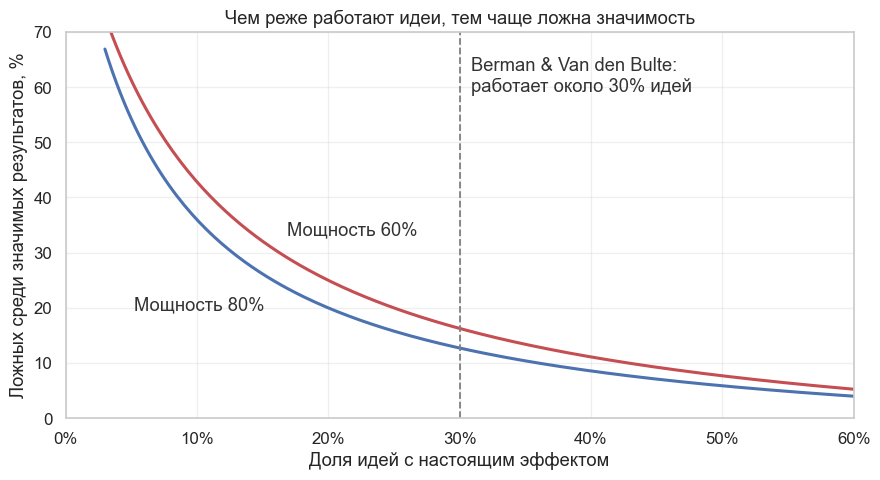

Работает 10% идей, мощность 80%: ложных 36%
Работает 10% идей, мощность 60%: ложных 43%
Работает 30% идей, мощность 80%: ложных 13%
Работает 30% идей, мощность 60%: ложных 16%


In [2]:
def false_discovery_rate(prior, power, alpha=ALPHA):
    return alpha * (1 - prior) / (alpha * (1 - prior) + power * prior)


priors = np.linspace(0.03, 0.6, 200)
curves = [(0.8, BLUE, 'Мощность 80%'), (0.6, RED, 'Мощность 60%')]

fig, ax = plt.subplots(figsize=(9, 5))
for power, color, label in curves:
    ax.plot(priors, 100 * false_discovery_rate(priors, power), color=color, lw=2.2)
    ax.annotate(label, (0.16, 100 * false_discovery_rate(0.16, power)), color='#333333',
                xytext=(8, 8) if power < 0.7 else (-8, -10), textcoords='offset points',
                ha='left' if power < 0.7 else 'right', va='bottom' if power < 0.7 else 'top')

ax.axvline(0.3, color=GRAY, ls='--', lw=1.3)
ax.annotate('Berman & Van den Bulte:\nработает около 30% идей', (0.3, 62), xytext=(8, 0),
            textcoords='offset points', color='#333333', va='center')
ax.set(xlim=(0, 0.6), ylim=(0, 70),
       xlabel='Доля идей с настоящим эффектом',
       ylabel='Ложных среди значимых результатов, %',
       title='Чем реже работают идеи, тем чаще ложна значимость')
ax.xaxis.set_major_formatter(lambda x, _: f'{100 * x:.0f}%')
plt.tight_layout()
plt.show()

for prior in (0.1, 0.3):
    for power, _, _ in curves:
        print(f'Работает {prior:.0%} идей, мощность {power:.0%}: ложных {false_discovery_rate(prior, power):.0%}')

При доле работающих идей 30% и мощности 60% формула даёт 16%, это близко к нижней границе оценки Berman и Van den Bulte. При доле 10% ложной становится уже больше трети значимых результатов, даже при мощности 80%.

Не путайте доли: 12% побед у Spotify не равны $\pi$, потому что победа это наблюдаемый итог теста, а не истинное свойство идеи. График показывает логику, а не оценку FDR для конкретной компании. Данные Optimizely к тому же собраны в 2014 году и относятся к метрике вовлечённости на сайтах, так что крупные продуктовые платформы могут выглядеть иначе. Похоже высокую долю нулевых эффектов авторы отмечают и для Bing.

К ложным открытиям добавляется **проклятие победителя** (1.06): среди выбранных тестов оценка эффекта завышена, поэтому сумма запущенных приростов почти всегда больше, чем реальный рост метрики.

### Как сравнивать правила решений

Если отдельный тест ненадёжен, надо оценивать не тест, а **правило решений**: стандартную процедуру, которая по результатам эксперимента выбирает вариант для запуска. Например: «запускаем вариант с наибольшим значимым ростом прокси-метрики, если не просели защитные метрики».

Netflix предлагает сравнивать правила по **суммарной отдаче**: сколько выросла бы главная метрика, если бы все прошлые эксперименты решались этим правилом ([Chou et al., KDD'25](https://arxiv.org/abs/2502.08763) **[рец.]**).

Наивный расчёт здесь ломается из-за проклятия победителя: одни и те же данные и выбирают вариант, и оценивают его выигрыш. Причём смещение не уходит с ростом числа экспериментов, пока размер каждого конечен. Решение: **разбиение экспериментов**: каждый тест случайно делим на части, на одной выбираем вариант, на другой измеряем его эффект. Шум в двух частях независим, поэтому выбор по шуму перестаёт давать выигрыш.

На 123 прошлых тестах новое правило с новой прокси-метрикой дало оценку суммарной отдачи более чем на 33% выше, и компания его приняла.

Важно смотреть на детали:

* p-value этого сравнения составляет 0.07–0.09. Авторы рекомендовали правило, потому что на кону много, а внедрение стоит мало. Это решение в логике ценности, а не значимости.
* Выигрыш дала небольшая группа тестов, где новая метрика резко разошлась со старой. Каждый из них по отдельности не имел мощности на главную метрику.
* Метод предполагает, что эффекты разных тестов независимы, а будущие эксперименты похожи на прошлые.

### Что считать успехом программы

Доля побед плохо описывает работу программы: нейтральный, но убедительный результат тоже полезен. Spotify ввёл метрику **эксперименты с выводом**. Эксперимент засчитывается, если он валиден и даёт основание для решения: запускать, откатить из-за просадки или признать эффект нейтральным, когда мощности для этого хватало **[блог]**.

Такой вывод даёт в среднем 64% экспериментов, а по командам разброс от 16% до 76%. Метрика показывает другое узкое место: не только мало побед, но и часть тестов не даёт вообще никакого вывода. Подход пока описан только самой компанией, сравнивать проценты между компаниями нельзя.

### Много маленьких тестов или мало больших

[Azevedo et al.](https://econpapers.repec.org/RePEc:ucp:jpolec:doi:10.1086/710607) **[рец.]** показывают, что ответ зависит от хвостов распределения эффектов. Если хвосты тонкие, лучше мало мощных тестов. Если очень толстые, лучше больше идей с меньшими выборками: основной выигрыш дают редкие крупные удачи, а их видно и на малых данных.

На данных Bing хвосты оказались очень толстыми. В модели авторов рост числа идей на 20% при том же числе пользователей поднимает продуктивность примерно на 17%. Это контрфактический расчёт в предположении, что новые идеи не хуже старых.

Отсюда прямое напряжение с первой частью раздела: больше тестов с малой мощностью дают больше крупных находок, но и больше ложных. Универсального ответа нет, он зависит от продукта и цены ошибки. Именно поэтому компании и переходят к оценке правил на собственной истории.

## Долгосрочные эффекты

Бизнес живёт кварталами и годами, а типичный тест идёт неделю или две. Стандартная задача выглядит так: предсказать эффект изменения ранжирования на DAU через 6 месяцев по вовлечённости за 7 дней.

Главный свежий источник здесь: [Sigerson et al., август 2026](https://arxiv.org/abs/2608.08043) **[преп., эксп.]**. Это итог воркшопа с 26 экспертами из 15 платформ и 4 университетов, среди них Netflix, Meta, Google, Pinterest и Airbnb. Такой документ фиксирует согласованный опыт, а не измерение. Авторы сами пишут, что систематических открытых данных о траекториях эффектов мало.

### Как ведёт себя эффект со временем

**Знак обычно сохраняется.** Участники считают смену знака редкой и думают, что в публикациях она преувеличена: такие истории интереснее. Исключения сосредоточены в трёх областях:

| Область | Что происходит | Пример |
|---|---|---|
| Сигналы качества контента | Сначала вовлечённость падает, потом растёт | YouTube понизил «бульварные» видео: через три недели время просмотра было ниже на 0.5%, через три месяца выше контроля |
| Сигналы качества контента | Сначала рост, потом падение | Facebook ослабил учёт качества в ранжировании: через месяц активность выше, через два года ниже |
| Гипермонетизация | Выручка растёт сейчас и падает из-за оттока | Игровые платформы |
| Цены | Смещение из-за срока до брони | Эксперименты с ценами в Airbnb |

**Размер эффекта меняется часто.** У Pinterest эффект от бейджей упал с 7% до 2.5%, но остался положительным. У Pandora через год эффект рекламной нагрузки мог более чем вдвое превышать эффект через два месяца. Метрики удержания особенно инертны: в ранжировании соцсетей половина долгосрочного эффекта на DAU набирается примерно за месяц.

**Про новизну согласия нет.** Участники считают сдвиг в первые дни частым, но расходятся в том, меняет ли он решения. Одна платформа просто отбрасывает первые дни, другие не видят в этом нужды.

### Суррогаты

**Суррогат** это короткая метрика или их комбинация, которая заменяет долгосрочный исход. **Суррогатный индекс** ([Athey, Chetty, Imbens, Kang](https://opportunityinsights.org/paper/the-surrogate-index/) **[рец.]**) предсказывает долгий исход по коротким метрикам и применяется к тесту. Простейший вариант это **автосуррогат**: та же метрика, только за короткий срок.

Неожиданный вывод воркшопа: автосуррогат часто трудно превзойти. Лучшая открытая проверка: [200 тестов Netflix](https://arxiv.org/abs/2311.11922) **[преп.]**, 14 дней против 63.

* Выводы совпали примерно в 95% случаев.
* Точность 79%, полнота 65% для решения «запускать».
* Ни разу суррогат не велел запустить то, что на прямом замере значимо ухудшало метрику.

Цифру 95% нельзя читать как «суррогат почти всегда прав». Большинство результатов незначимы (около 86.5% у суррогата и 79% на двух месяцах), а согласие двух незначимых результатов мало что говорит. Честнее полнота: каждый третий хороший запуск был бы пропущен. Авторы при этом считают, что сокращение цикла окупает потери. Данные относятся к алгоритмам персонализации, а «долго» здесь значит два месяца, а не годы.

Откуда брать суррогат, тоже вопрос:

| | Наблюдательный | Экспериментальный |
|---|---|---|
| На чём учится | История пользователей | Набор прошлых длинных тестов |
| Главный риск | Активные пользователи активны и потом, это не причинность | Шумные эффекты дают ложную связь между метриками |
| Чего требует | Сильных допущений | Много длинных представительных тестов, которых почти ни у кого нет |
| Мнение участников | Может давать согласованные решения, даже если смещён | Предпочтительнее, когда это возможно |

У обоих подходов есть ловушки:

* **Ложная связь на шуме.** Если регрессировать эффекты на долгую метрику по эффектам на короткую, связь появится даже на случайных перемешиваниях групп: шум у метрик коррелирован. Один из способов борьбы тот же, что у Netflix выше: разбиение экспериментов.
* **Узкие интервалы.** Суррогат даёт точную оценку, но интервал не учитывает смещение. Точная оценка, которую потом опровергли, сильно бьёт по доверию.
* **Подгонка под метрику.** Историческая связь рушится, когда команды начинают двигать короткую метрику напрямую. Пример участников: уведомления раз в 7 дней ради вовлечённости на 7-й день.
* **Перенос между классами.** Суррогат с тестов уведомлений может обмануть на тестах ранжирования.

Эксперты также ценят простоту. Сложный индекс теряет доверие, если нельзя объяснить, почему он сдвинулся. Цель не несмещённая оценка, а лучшее решение. Главный вывод статьи: **хорошо проведённый длинный эксперимент незаменим**, хотя бы чтобы проверить суррогат.

Открытыми остаются меняющееся воздействие (за время длинного холдаута продукт обновляется, и эффект относится уже к цепочке изменений), постоянные воздействия, которые не проходят только через короткие метрики, и смещение выборки в сторону активных пользователей.

## Интерференция и пересечение тестов

Классическую интерференцию мы разбирали в 2.02 и 2.03: маркетплейсы, сети, общие ресурсы. Здесь два новых её лица.

### Symbiosis bias: группы обучают одну модель

Представим A/B-тест двух рекомендательных алгоритмов. Обе группы пишут логи в общий пул, на котором обе модели дообучаются. Тогда алгоритм контроля учится на данных, которых без теста не существовало бы. В разговоре о SUTVA обычно думают об отсутствии влияния между пользователями, но здесь нарушено другое условие: **нет скрытых вариантов воздействия**. Результат пользователя зависит не только от алгоритма, но и от данных, на которых тот обучен.

[Brennan et al., WWW'25](https://arxiv.org/abs/2309.07107) **[рец.]** назвали это **symbiosis bias** и сравнили три дизайна:

| Дизайн | Как устроен | Цена |
|---|---|---|
| Кластерный | Рандомизируем кластеры похожих пользователей | Меньше эффективных единиц, выше разброс, нужны хорошие кластеры |
| С разделением данных | Каждая модель учится только на данных своей группы | Малой группе достаётся меньше данных для обучения |
| Совместное разделение пользователей и объектов | Пользователи каждой группы видят только свои объекты | Каждой группе доступен только свой кусок каталога |

Каждый дизайн снижает смещение, но ни один не бесплатен. Какой лучше, зависит от размера теста, качества кластеров и размера каталога.

Полевое свидетельство такое. В тесте по странам на промышленной рекомендательной системе изменение усиливало показ свежего контента. Просмотры свежего контента в контрольных странах росли вместе с их близостью к тестовым, а в тестовых странах такой связи почти не было. Значит, данные «протекают» из теста в контроль, причём асимметрично. Это корреляция на одном тесте, а не оценка общего масштаба. Сколько смещения symbiosis bias вносит в типичный тест, по прочитанным работам сказать нельзя.

Есть и подход на уровне анализа: взвешенное обучение в работе [Si](https://arxiv.org/abs/2310.17496) **[преп.]**. Проблема особенно важна для всего, что обучается на лету. С ней же связан вопрос из прошлого раздела: на длинном тесте адаптивная модель меняется сама, даже без разработчиков.

### Пересечение тестов

Когда тысячи тестов идут одновременно, бывают два случая. **Коллизии** ломают интерфейс, такие тесты разводят слоями или по времени. **Взаимодействия** ничего не ломают, но искажают оценки. Прошлые работы указывают, что большинство взаимодействий малы, поэтому массовая проверка всех пар не всегда нужна. Но отдельные случаи бывают дорогими.

Игрушечный пример из препринта LinkedIn ([Hosseini, 2026](https://arxiv.org/abs/2604.16671) **[преп.]**). Первый вариант сам по себе даёт +3, второй +4, а вместе они дают −3 там, где пересекаются. Если анализировать тесты по отдельности или запускать по очереди, оба выглядят положительными, и запускаются оба с итогом +2.25. Лучше запустить только второй: +3.87.

Метод Multi-Experiment Analysis оценивает пересекающиеся тесты совместно и отвечает на вопросы, близкие к реальному запуску: эффект с поправкой на другие тесты, эффект любой комбинации вариантов, эффект при условии, что чужой тест запустят. Дизайн факторного эксперимента заранее не нужен, но назначения должны быть независимы. Автор сообщает о сотнях анализов более чем в восьми продуктовых направлениях. Неожиданно полезной оказалась отладка: инструмент помогал находить ошибки конфигурации. Это описание одной компании, сама статья пока препринт.

### Масштаб как проблема

Многие старые проблемы возвращаются из-за масштаба. В Авито один эксперимент даёт 10–30 тысяч p-value, а 250+ команд считали одни и те же метрики по-разному, что потребовало единого слоя определений **[блог]**. Множественные сравнения (1.03) здесь уже вопрос не только формулы, но и того, какие метрики вообще смотреть. Инженерная сторона относится к теме платформ в лекции 3.02.

## A/B для AI-продуктов

В AI-продукте изменением может быть правка промпта, новый поиск по базе знаний или замена модели. Практические советы здесь в основном идут из блогов: ответ случаен даже при одинаковом запросе, новизна в первые дни высока, а удержание двигается медленно. Строгих работ пока мало, но две идеи уже оформились.

### Когда хватит оффлайн-оценок

**Оффлайн-оценка** (eval) это набор проверок на фиксированных запросах, часто с другой LLM в роли судьи. Команды хотят решать по ней: это быстро и дёшево. Обычно проверяют, согласен ли судья с людьми. [Schultzberg, октябрь 2026](https://arxiv.org/abs/2610.10142) **[преп.]** показывает, что это другой вопрос.

Решению о запуске нужна **суррогатность на уровне изменений**: предсказывает ли сдвиг оффлайн-оценки сдвиг онлайн-метрики на множестве похожих изменений. Судья может отлично совпадать с людьми, а его сдвиг может ничего не говорить о знаке онлайн-эффекта.

Вот что из этого следует:

* **Шум занижает связь.** В журнале прошлых запусков и оффлайн-оценка, и онлайн-эффект измерены с шумом. Поправка вычитает известные дисперсии из ковариации, как в мета-анализе (3.01).
* **Судья может перевернуть знак.** Если судья одинаково точен на обоих вариантах, эффект только масштабируется. Если точность зависит от варианта, бывает так: судья на 3 процентных пункта менее чувствителен к ответам нового варианта, и настоящее улучшение на +2.0 п. п. превращается в −0.25 п. п. Больше задач в наборе делают эту ошибку точнее, а не меньше.
* **Смешивание классов создаёт ложную связь.** Промпты, поиск и смена модели могут отличаться по среднему и по обеим метрикам сразу. В расчёте из статьи внутри каждого класса связи нет ($R^2 = 0$), а в смеси $R^2 = 0.81$. Авторы сравнивают это с парадоксом Симпсона.
* **Решение убирает данные.** Как только команда начала запускать без теста, связь больше не наблюдается в этой области, и её дрейф незаметен. Нужны случайные **контрольные эксперименты**.

Итог: правило из трёх исходов. Запускаем, отклоняем или отправляем в A/B, с порогами из допустимого риска запустить вредное изменение.

Проверку на открытых данных легко прочитать неверно, поэтому посмотрим внимательно. На 183 заголовках Upworthy связь почти нулевая ($R^2 = 0.023$), порог запуска недостижим, и все изменения уходят в A/B. Но это не приговор оффлайн-оценкам. Здесь судья оценивал информативность заголовка, а онлайн-метрикой были клики: расхождение заложено специально, чтобы показать работу процедуры. Это и не LLM-продукт. Первые компании уже сравнивают сдвиги оценок с онлайн-результатами, но журналы запусков обычно закрыты, так что открытых проверок таких правил пока мало.

### Кейс: подхалимство GPT-4o

В апреле 2025 года OpenAI выпустила обновление GPT-4o и через несколько дней откатила его: модель стала чрезмерно соглашаться с пользователями. По пересказам разбора компании ([TechCrunch](https://techcrunch.com/2025/04/29/openai-explains-why-chatgpt-became-too-sycophantic), [Cointelegraph](https://cointelegraph.com/news/openai-ignored-experts-overly-agreeable-chatgpt-model-release)):

* обновление слишком опиралось на краткосрочную обратную связь и не учитывало, как со временем меняется взаимодействие;
* отдельный сигнал обратной связи ослабил основной, сдерживавший подхалимство;
* сигналы пользователей были положительными, хотя часть экспертов считала поведение странным, а подхалимство отдельно не отслеживалось.

Это история не о плохой статистике. Метрика была положительной, но измеряла не то, что важно. По структуре это близко к сигналам качества контента из раздела о долгосрочных эффектах, где краткосрочная реакция и долгий результат могут расходиться. Сравнение наше, а не OpenAI: компания описывала прежде всего обучение модели, и деталей своих экспериментов в этих пересказах она не раскрывает.

## Модели вместо людей

Если A/B дорог, почему бы не показать варианты LLM с ролью пользователя? Это самая обсуждаемая новая идея в области. Самая точная формулировка её проблемы у [Persson, Schultzberg, Ankargren, июнь 2026](https://arxiv.org/abs/2606.17165) **[преп.]**:

> A/B-тест на людях верен по построению, а на ответах LLM только при выполнении допущений. И эти допущения труднее всего оправдать там, где от LLM ждут наибольшей пользы.

Авторы рассматривают ответ модели как суррогатный исход: реальных людей всё равно нужно измерить, чтобы откалибровать модель. Если поставить две самые прикладные работы рядом, видно, что ошибка бывает в обе стороны:

| | Spotify (Persson et al.) | Amazon ([Hut, Masoero](https://arxiv.org/abs/2608.02345)) |
|---|---|---|
| Статус | **[преп.]** | **[рец.]**, воркшоп на COLM 2026 |
| Данные | 417 тестов заголовков Upworthy, вопрос в заголовке или нет | 67 маркетинговых A/B-тестов |
| Сырая модель | 39% реального эффекта, занижение | Завышает размер эффекта |
| Эффект калибровки | До 62–68% с нелинейной моделью, разрыв перестаёт быть значимым | Квадрат ошибки ниже примерно в 77 раз |
| Решение о запуске | Не оценивалось | Совпадение 0.41 при случайном уровне 0.33, без калибровки |

Осторожнее со словом «угадывает». У Amazon знак совпал в 70% тестов, и это звучит хорошо. Но правило «всегда положительный» даёт 57%, а повтор того же реального теста совпадает по знаку с оригиналом только в 69%. Авторы прямо пишут, что такое совпадение не является явным свидетельством направленного сигнала на этом шумном наборе. Завышение они объясняют тем, что модели реагируют на различия решительнее людей.

Проценты из таблицы нельзя переносить на другие задачи: в обеих работах это один узкий тип изменений, в основном тексты и клики. Калибровка на истории к тому же не гарантирует результат на новом типе изменений. Сейчас разумная роль таких симуляций это отсев явно плохих идей до теста, и даже для неё нужны данные лучше имеющихся.

Система [Agent A/B](https://arxiv.org/abs/2504.09723) **[рец., CHI EA'26]** запускает агентов с персонами на живом сайте. В кейсе на Amazon.com 1 000 агентов воспроизвели направление реального теста панели фильтров. Это один кейс, и авторы подчёркивают, что система дополняет тесты на людях, а не заменяет их.

### Агенты ведут эксперименты

Параллельно LLM начинают придумывать варианты и запускать циклы тестов. [A/B Agent](https://arxiv.org/abs/2608.04625) **[преп.]** автоматизирует подбор стратегии ранжирования на истории прошлых тестов и сообщает о росте GMV на 4.829% в системе коротких видео. Компания не названа, цифра дана одним онлайн-результатом, независимой проверки нет. [Adobe](https://arxiv.org/abs/2602.13852) встроил в продукт ранжирование кандидатов и подсказки новых вариантов, потому что трафика на все варианты не хватает.

Здесь сходятся нити лекции. Если вариантов становится намного больше, а трафик прежний, снижаются мощность и доля настоящих эффектов среди проверяемых идей. На графике из раздела о ценности решений это движение влево и вверх. Автоматизация без оценки правил решений может дать больше тестов и меньше ценности. Это наше рассуждение, прямых измерений пока нет.

### Агенты как трафик

Третий сценарий: агенты приходят на сайт вместо людей, попадают в обе группы и реагируют не так, как люди. Поставщики защиты от ботов и аналитики сообщают о быстром росте такого трафика **[вендор]**, но это те, кто продаёт решение. Исследований, измеряющих влияние на результаты A/B-тестов, мы не нашли. Механизм реалистичен, а масштаб неизвестен. Практический минимум: выделять автоматизированные сессии и проверять, не меняется ли их доля между группами.

## Открытые вопросы

| Раздел | Что не решено |
|---|---|
| Ценность решений | Как оценивать правила, когда эффекты тестов зависимы, а продукт меняется. Как выбрать между числом тестов и их мощностью |
| Долгосрочные эффекты | Систематических открытых данных о траекториях мало. Как оценивать меняющееся воздействие. Как учесть смещение к активным пользователям |
| Интерференция | Каков типичный размер symbiosis bias. Как проверять взаимодействия без перебора всех пар |
| AI-продукты | Предсказывают ли оффлайн-оценки онлайн-эффект на реальных журналах запусков. Какие метрики ловят вред, не видимый в реакции пользователя |
| Модели вместо людей | Когда калибровка переносится на новые изменения. Сколько реальных людей нужно для проверки |
| Агенты | Какова реальная доля агентов в тестах. Как защищать программу от потока слабых автоматических вариантов |

На открытых данных тоже держится не всё: две важные работы про LLM опираются на архив заголовков Upworthy 2013–2015 годов, потому что других открытых данных тестов почти нет. Авторы обзора Larsen et al. называют эту закрытость отдельной проблемой, и она остаётся актуальной.

**Заметка о рынке.** Ландшафт инструментов быстро меняется. В 2025 году Datadog купил Eppo, а OpenAI купил Statsig. В мае 2026 года бренд и клиенты Statsig перешли к Amplitude, а команда осталась в OpenAI. Эксперименты всё плотнее срастаются с аналитикой и разработкой AI, поэтому привязываться к конкретной платформе рискованно.

## Заключение

* Базовая статистика A/B в крупных платформах уже встроена. Фронт сместился к ценности всего потока тестов, коротким замерам, обучающимся системам и AI-продуктам.
* Большинство идей не работает, поэтому значимость часто ложна, и главная причина тут доля нулевых идей, а не мощность. Правила решений стоит сравнивать по суммарной отдаче на прошлых тестах с защитой от проклятия победителя.
* Знак эффекта со временем меняется редко, кроме качества контента, монетизации и цен. Размер меняется часто. Простой суррогат трудно превзойти, но длинный эксперимент всё равно нужен для проверки.
* Общие данные обучения создают новую интерференцию, а пересечение тестов иногда скрывает лучшую комбинацию. Оба эффекта реальны, их типичный размер неизвестен.
* Для AI-продукта вопрос не в том, согласен ли судья с людьми, а в том, предсказывает ли оффлайн-сдвиг онлайн-эффект на таких же изменениях. Кейс GPT-4o напоминает, что положительный короткий сигнал может мерить не то.
* LLM вместо людей пока ошибается в размере эффекта в обе стороны и требует калибровки на людях. Заявления о замене A/B сильно опережают данные.
* Эта лекция быстрее других устареет. Смотрите на статус источника и проверяйте выводы на своём продукте.

**Источники:** основные работы перечислены в README занятия.